# DL4STG PA3
### Saim Bilal - 27100208

### 1(a) Affine Messages and Lost Information

With the affine message function $\phi(x) = wx + c$, summing over all neighbours $u \in N(v)$ gives

$$\sum_{u \in N(v)} \phi(x_u) = \sum_{u \in N(v)} (wx_u + c) = w \sum_{u \in N(v)} x_u + c \sum_{u \in N(v)} 1 = w S_v + c n_v.$$

Passing this sum into $\rho$ yields

$$h_v = \rho(w S_v + c n_v).$$

The function $\rho$ receives only the single scalar $w S_v + c n_v$ rather than the individual sensor readings. Whenever two neighbourhoods share the same size $n_v$ and the same total trend $S_v$, the value $w S_v + c n_v$ is identical for any choice of parameters $w$ and $c$. Because $\rho$ acts on that number alone, it must return the exact same output $h_v$ for both neighbourhoods.

As an example, consider two neighbourhoods of size $n_v = 2$:
* Neighbourhood A has trends $(-1, +1)$, giving $n_v = 2$, $S_v = 0$, and $0$ steady neighbours.
* Neighbourhood B has trends $(0, 0)$, giving $n_v = 2$, $S_v = 0$, and $2$ steady neighbours.

In both cases the aggregated message simplifies to $w(0) + c(2) = 2c$, so no choice of $w$, $c$, or $\rho$ can tell them apart.

### 1(b) Encoding All Three Counts in a Single Number

Let $c_{-1}$, $c_0$, and $c_1$ denote the numbers of slowing ($-1$), steady ($0$), and speeding-up ($+1$) neighbours. Since $1 \le |N(v)| \le K$, each count is an integer between $0$ and $K$.

To store all three counts in separate digits of one integer without carries between place values, the base $B$ must be greater than the maximum possible digit $K$. Setting $B = K + 1$ guarantees no carries occur, since every count satisfies $0 \le c_i \le K < K + 1$.

Using base $K + 1$, define the message values as:
* $\phi(-1) = 1$
* $\phi(0) = K + 1$
* $\phi(1) = (K + 1)^2$

Summing over the neighbourhood gives the base-$(K + 1)$ integer

$$M = \sum_{u \in N(v)} \phi(x_u) = c_{-1} + c_0 (K + 1) + c_1 (K + 1)^2.$$

Because each coefficient lies in $\{0, 1, \dots, K\}$, this representation is unique. We recover all three counts using integer division and remainder arithmetic:
* $c_{-1} = M \bmod (K + 1)$
* $c_0 = \lfloor M / (K + 1) \rfloor \bmod (K + 1)$
* $c_1 = \lfloor M / (K + 1)^2 \rfloor$

#### Simpler Target

If we only want the count of non-steady neighbours ($-1$ or $+1$), we set:
* $\phi(-1) = 1$
* $\phi(0) = 0$
* $\phi(1) = 1$

The sum $\sum_{u \in N(v)} \phi(x_u) = c_{-1} + c_1$ directly equals the number of non-steady neighbours regardless of neighbourhood size.

In [ ]:
import numpy as np

K = 8
base = K + 1

phi = {-1: 1, 0: base, 1: base**2}

# generate all valid triples
triples = [
    (c_m1, c_0, c_1)
    for c_m1 in range(K + 1)
    for c_0 in range(K + 1)
    for c_1 in range(K + 1)
    if 1 <= c_m1 + c_0 + c_1 <= K
]

sums = []
for c_m1, c_0, c_1 in triples:
    neighbours = np.array([-1] * c_m1 + [0] * c_0 + [1] * c_1)
    M = sum(phi[x] for x in neighbours)
    sums.append(M)

    rec_m1 = M % base
    rec_0 = (M // base) % base
    rec_1 = M // (base**2)

    assert (rec_m1, rec_0, rec_1) == (c_m1, c_0, c_1), f"Mismatch for {(c_m1, c_0, c_1)}"

assert len(set(sums)) == len(triples), "Encoded sums are not unique!"
print(f"Verified all {len(triples)} valid triples for K = {K}: all sums unique and exact.")

Verified all 164 valid triples for K = 8: all sums unique and exact.


### 1(c) Comparing Sum, Mean, and Max Aggregation

Let $z = (z_1, z_2, z_3)$ denote the aggregated vector passed to $\rho$, and let $c_{-1}, c_0, c_1$ be the counts of slowing, steady, and speeding-up neighbours in a neighbourhood of size $n_v = c_{-1} + c_0 + c_1 \in \{1, \dots, 8\}$.

| Task | Method | Possible? | Reason |
| :--- | :--- | :--- | :--- |
| (i) Count steady neighbours | Sum | Yes | $\rho$ reads the second coordinate $z_2$, which directly equals the steady neighbour count $c_0$. |
| (i) Count steady neighbours | Mean | No | Neighbourhood $A = (0)$ and Neighbourhood $B = (0, 0)$ both produce the mean vector $(0, 1, 0)$, even though the correct count is $1$ for $A$ and $2$ for $B$. |
| (i) Count steady neighbours | Max | No | Neighbourhood $A = (0)$ and Neighbourhood $B = (0, 0)$ both produce the max vector $(0, 1, 0)$, even though the correct count is $1$ for $A$ and $2$ for $B$. |
| (ii) Decide whether more than half of the neighbours are slowing | Sum | Yes | $\rho$ sums all three coordinates to recover $n_v = z_1 + z_2 + z_3$ and checks whether $z_1 > \frac{1}{2}(z_1 + z_2 + z_3)$. |
| (ii) Decide whether more than half of the neighbours are slowing | Mean | Yes | The first coordinate $z_1 = c_{-1} / n_v$ is already the fraction of slowing neighbours, so $\rho$ checks whether $z_1 > 0.5$. |
| (ii) Decide whether more than half of the neighbours are slowing | Max | No | Neighbourhood $A = (-1, -1, 0)$ and Neighbourhood $B = (-1, 0, 0)$ both produce the max vector $(1, 1, 0)$, even though the answer is Yes for $A$ ($2/3 > 1/2$) and No for $B$ ($1/3 \le 1/2$). |
| (iii) Decide whether any neighbour is slowing | Sum | Yes | $\rho$ reads the first coordinate $z_1 = c_{-1}$ and outputs Yes if $z_1 \ge 1$ (or $z_1 > 0$). |
| (iii) Decide whether any neighbour is slowing | Mean | Yes | Since $n_v \ge 1$, the first coordinate $z_1 = c_{-1} / n_v$ is positive if and only if $c_{-1} \ge 1$. $\rho$ outputs Yes if $z_1 > 0$. |
| (iii) Decide whether any neighbour is slowing | Max | Yes | The first coordinate $z_1$ equals $1$ when at least one neighbour has trend $-1$ and $0$ otherwise, so $\rho$ outputs Yes if $z_1 = 1$. |

### 2(a)(i) Fitting Symmetric Weights on an Isolated Slowdown

At time $t$, sensor $20$ has reading $x_{20}(t) = 1$ and every other sensor has reading $0$. Under the true backward-motion rule $x_i(t + 1) = x_{i+1}(t)$, the slowdown moves to sensor $19$ at time $t + 1$, so $x_{19}(t + 1) = 1$ and $x_i(t + 1) = 0$ for all $i \neq 19$.

Using the symmetric layer $\hat{x}_i(t + 1) = a x_i(t) + b(x_{i-1}(t) + x_{i+1}(t))$, the predicted and true readings at sensors $19$, $20$, and $21$ are:

| Sensor $i$ | Predicted $\hat{x}_i(t + 1)$ | True $x_i(t + 1)$ |
| :--- | :--- | :--- |
| $19$ | $a(0) + b(0 + 1) = b$ | $1$ |
| $20$ | $a(1) + b(0 + 0) = a$ | $0$ |
| $21$ | $a(0) + b(1 + 0) = b$ | $0$ |

At every other sensor $i \notin \{19, 20, 21\}$, both the predicted and true values are $0$. The sum of squared prediction errors across all $40$ sensors is therefore

$$E(a, b) = \sum_{i=0}^{39} \bigl(\hat{x}_i(t + 1) - x_i(t + 1)\bigr)^2 = (b - 1)^2 + (a - 0)^2 + (b - 0)^2 = a^2 + 2b^2 - 2b + 1.$$

Taking partial derivatives with respect to $a$ and $b$ and setting them to zero gives:

$$\frac{\partial E}{\partial a} = 2a = 0 \implies a = 0,$$

$$\frac{\partial E}{\partial b} = 4b - 2 = 0 \implies b = 0.5.$$

$(a, b) = (0, 0.5)$ minimizes the squared error.

### 2(a)(ii)

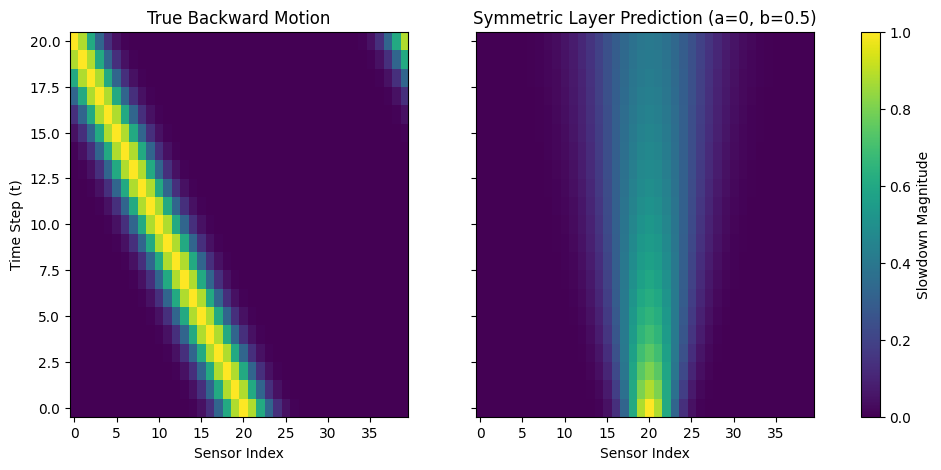

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# initial smooth bump at t = 0
sensors = np.arange(40)
x0 = np.exp(-((sensors - 20) ** 2) / 8.0)

steps = 20
true_history = np.zeros((steps + 1, 40))
pred_history = np.zeros((steps + 1, 40))

true_history[0] = x0
pred_history[0] = x0

# fitted parameters from (a)(i): a = 0, b = 0.5
a, b = 0.0, 0.5

for t in range(steps):
    # True rule
    true_history[t + 1] = np.roll(true_history[t], -1)
    
    x_curr = pred_history[t]
    pred_history[t + 1] = a * x_curr + b * (np.roll(x_curr, 1) + np.roll(x_curr, -1))

# heatpmap
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

vmin, vmax = 0.0, 1.0

im0 = axes[0].imshow(true_history, aspect="auto", origin="lower", vmin=vmin, vmax=vmax, cmap="viridis")
axes[0].set_title("True Backward Motion")
axes[0].set_xlabel("Sensor Index")
axes[0].set_ylabel("Time Step (t)")

im1 = axes[1].imshow(pred_history, aspect="auto", origin="lower", vmin=vmin, vmax=vmax, cmap="viridis")
axes[1].set_title("Symmetric Layer Prediction (a=0, b=0.5)")
axes[1].set_xlabel("Sensor Index")

fig.colorbar(im1, ax=axes.ravel().tolist(), label="Slowdown Magnitude")
plt.show()

#### Comparison of Bump Motion and Shape

Under the true rule, the slowdown bump travels steadily to the left by one sensor per time step while keeping its original height and width intact. Under the symmetric graph layer, the bump never shifts its center from sensor $20$, and instead spreads outward and flattens into a wider, lower peak over time.

### 2(b) Directional Weights and 1D Convolution

To match the true rule $x_i(t + 1) = x_{i+1}(t)$ in the directional layer $\hat{x}_i(t + 1) = a x_i(t) + w_- x_{i-1}(t) + w_+ x_{i+1}(t)$, set:

$$a = 0, \quad w_- = 0, \quad w_+ = 1.$$

Substituting these values into the layer equation gives

$$\hat{x}_i(t + 1) = 0 \cdot x_i(t) + 0 \cdot x_{i-1}(t) + 1 \cdot x_{i+1}(t) = x_{i+1}(t),$$

which reproduces the exact next snapshot for every sensor $i$ and any input $x(t)$.

#### Why This Removes the Difficulty in (a)

Giving the two neighbours separate weights breaks the reflection symmetry around each sensor. Instead of forcing the layer to average the sensors ahead and behind equally, the separate weights let the layer copy the reading exclusively from the sensor ahead ($i + 1$) and ignore the sensor behind ($i - 1$).

#### 1D Convolution Implementation

* **Kernel entries:** $[0, 0, 1]$, ordered to multiply $[x_{i-1}, x_i, x_{i+1}]$.
* **Ring boundary handling:** Apply circular (wrap-around) padding of width $1$ to both ends of the $40$-sensor array before convolving (for example, `padding_mode="circular"` in PyTorch `Conv1d` or `mode="wrap"` in `np.pad`), so sensor $0$ uses sensor $39$ as $x_{-1}$ and sensor $39$ uses sensor $0$ as $x_{40}$.

### 2(c) Using History with Equal Spatial Weights

The layer with history is

$$\hat{x}_i(t + 1) = a x_i(t) + b\bigl(x_{i-1}(t) + x_{i+1}(t)\bigr) + c x_i(t - 1).$$

#### (i) Exact Coefficients for Backward Motion

Under backward motion, every reading shifts one sensor left per step: $x_i(t) = x_{i+1}(t - 1)$. Shifting the spatial index by $-1$ shows that the reading at sensor $i$ at time $t - 1$ has moved to sensor $i - 1$ at time $t$:

$$x_i(t - 1) = x_{i-1}(t).$$

Substituting $x_i(t - 1) = x_{i-1}(t)$ into the layer equation gives

$$\hat{x}_i(t + 1) = a x_i(t) + (b + c) x_{i-1}(t) + b x_{i+1}(t).$$

To match the true next snapshot $x_i(t + 1) = x_{i+1}(t)$ for every input, we set $a = 0$, $b = 1$, and $b + c = 0$, which yields:

$$a = 0, \quad b = 1, \quad c = -1.$$

Substituting these coefficients back verifies the exact prediction:

$$\hat{x}_i(t + 1) = 0 \cdot x_i(t) + 1 \cdot \bigl(x_{i-1}(t) + x_{i+1}(t)\bigr) - 1 \cdot x_i(t - 1) = x_{i-1}(t) + x_{i+1}(t) - x_{i-1}(t) = x_{i+1}(t).$$

#### (ii) Checking Forward Motion with the Same Coefficients

Under forward motion, the update rule is $x_i(t + 1) = x_{i-1}(t)$. Applying this rule one step earlier gives $x_i(t) = x_{i-1}(t - 1)$, so the previous reading at sensor $i$ is now at sensor $i + 1$:

$$x_i(t - 1) = x_{i+1}(t).$$

Substituting $x_i(t - 1) = x_{i+1}(t)$ and the same coefficients $(a, b, c) = (0, 1, -1)$ into the layer gives

$$\hat{x}_i(t + 1) = 0 \cdot x_i(t) + 1 \cdot \bigl(x_{i-1}(t) + x_{i+1}(t)\bigr) - 1 \cdot x_{i+1}(t) = x_{i-1}(t) + x_{i+1}(t) - x_{i+1}(t) = x_{i-1}(t).$$

The exact same coefficients still produce the exact next snapshot under forward motion.

#### (iii) How History Distinguishes Direction

A single snapshot shows where a slowdown is located, so summing both spatial neighbours equally ($x_{i-1}(t) + x_{i+1}(t)$) sends the wave in both directions at once. Because the previous reading $x_i(t - 1)$ equals whichever neighbour the pattern just came from ($x_{i-1}(t)$ when moving backward, or $x_{i+1}(t)$ when moving forward), subtracting $x_i(t - 1)$ cancels out the trailing side and leaves only the forward-moving side intact.

### 3(a)


5-minute shape (timestamps, sensors): (210528, 716)
Missing (NaN) entries: 7636666 (5.0662%)
Zero entries: 0.27%
15-minute tensor shape (T, N, F): (70176, 716, 1)


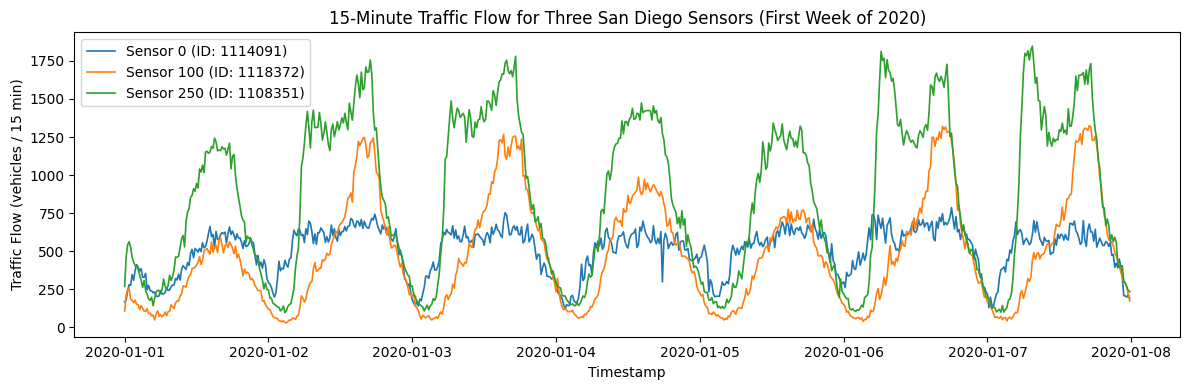

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

files = {}
for root, _, filenames in os.walk("/kaggle/input"):
    for fname in filenames:
        files[fname] = os.path.join(root, fname)

meta = pd.read_csv(files["ca_meta.csv"])
sd_indices = np.where(meta["District"] == 11)[0]

df_2020 = pd.read_hdf(files["ca_his_raw_2020.h5"]).iloc[:, sd_indices]
df_2021 = pd.read_hdf(files["ca_his_raw_2021.h5"]).iloc[:, sd_indices]

df_5min = pd.concat([df_2020, df_2021], axis=0)
if not isinstance(df_5min.index, pd.DatetimeIndex):
    df_5min.index = pd.date_range("2020-01-01 00:00:00", periods=len(df_5min), freq="5min")

df_5min = df_5min.loc["2020-01-01":"2021-12-31"]
print("5-minute shape (timestamps, sensors):", df_5min.shape)

# missign value handlig
nan_count = int(df_5min.isna().sum().sum())
nan_pct = 100.0 * nan_count / df_5min.size
zero_pct = 100.0 * (df_5min == 0).sum().sum() / df_5min.size
print(f"Missing (NaN) entries: {nan_count} ({nan_pct:.4f}%)")
print(f"Zero entries: {zero_pct:.2f}%")

df_clean = df_5min.interpolate(method="time", limit_direction="both").ffill().bfill()

# resampling
df_15min = df_clean.resample("15min").sum()
X = df_15min.to_numpy(dtype=np.float32)[..., np.newaxis]
print("15-minute tensor shape (T, N, F):", X.shape)


selected_positions = [0, 100, 250]
one_week = df_15min.iloc[:7 * 96, selected_positions]

plt.figure(figsize=(12, 4))
for col_pos, sensor_pos in enumerate(selected_positions):
    sensor_id = one_week.columns[col_pos]
    plt.plot(
        one_week.index,
        one_week.iloc[:, col_pos],
        label=f"Sensor {sensor_pos} (ID: {sensor_id})",
        linewidth=1.2,
    )

plt.title("15-Minute Traffic Flow for Three San Diego Sensors (First Week of 2020)")
plt.xlabel("Timestamp")
plt.ylabel("Traffic Flow (vehicles / 15 min)")
plt.legend()
plt.tight_layout()
plt.show()

### 3(a) Data Extraction, Resampling, and Missing Values

#### Aggregation Choice and Physical Units
In the LargeST dataset, raw traffic flow measurements record the number of vehicles passing a loop detector during each 5-minute window (units of vehicles per 5 minutes). Because each reading is an interval vehicle count rather than an instantaneous rate, consecutive 5-minute intervals are aggregated by **summation** into 15-minute bins:

$$X^{\text{15min}}_t = \sum_{k=0}^{2} X^{\text{5min}}_{3t+k}.$$

Summing three non-overlapping 5-minute counts preserves the physical meaning of the variable and converts the units cleanly from vehicles per 5 minutes to **vehicles per 15 minutes**, yielding a tensor of shape $(70176, 716, 1)$.

#### Missing Value Identification and Handling
Across the 2020 and 2021 5-minute records for all 716 San Diego sensors, there are $7,636,666$ missing (`NaN`) entries ($5.07\%$ of all observations), alongside $0.27\%$ zero readings. These gaps are filled prior to 15-minute summation using linear interpolation along the time axis, followed by forward and backward filling to cover any missing values at the boundaries of the two-year sequence. Filling gaps before resampling prevents a single dropped 5-minute reading from artificially depressing a 15-minute interval total.

### 3(b)

Number of nodes: 716
Nonzero edges (including self-loops): 18035
Nonzero edges (excluding self-loops): 17319
Is A_SD symmetric? False


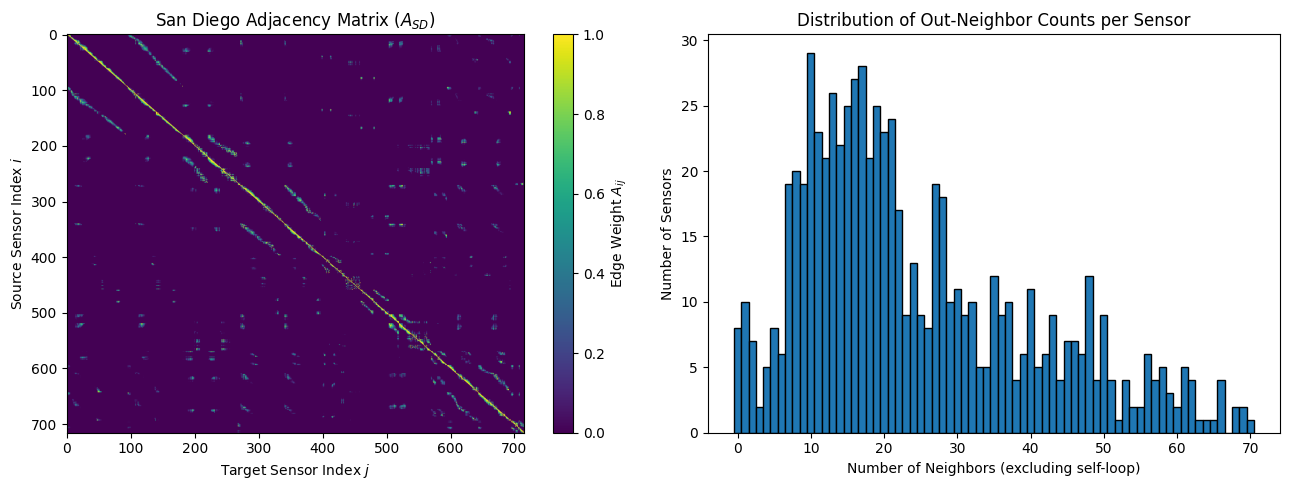

Out-neighbors summary -> min: 0, median: 20.0, max: 70


In [ ]:

A_ca = np.load(files["ca_rn_adj.npy"])
A_sd = A_ca[np.ix_(sd_indices, sd_indices)]

assert A_sd.shape == (716, 716), f"Expected (716, 716), got {A_sd.shape}"

num_nodes = A_sd.shape[0]
nonzero_total = int(np.count_nonzero(A_sd))

A_no_diag = A_sd.copy()
np.fill_diagonal(A_no_diag, 0)
nonzero_no_self = int(np.count_nonzero(A_no_diag))
is_symmetric = bool(np.allclose(A_sd, A_sd.T))

print(f"Number of nodes: {num_nodes}")
print(f"Nonzero edges (including self-loops): {nonzero_total}")
print(f"Nonzero edges (excluding self-loops): {nonzero_no_self}")
print(f"Is A_SD symmetric? {is_symmetric}")

out_neighbors = np.count_nonzero(A_no_diag, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

im = axes[0].imshow(A_sd, cmap="viridis", aspect="auto")
axes[0].set_title("San Diego Adjacency Matrix ($A_{SD}$)")
axes[0].set_xlabel("Target Sensor Index $j$")
axes[0].set_ylabel("Source Sensor Index $i$")
fig.colorbar(im, ax=axes[0], label="Edge Weight $A_{ij}$")

axes[1].hist(out_neighbors, bins=range(0, out_neighbors.max() + 2), edgecolor="black", align="left")
axes[1].set_title("Distribution of Out-Neighbor Counts per Sensor")
axes[1].set_xlabel("Number of Neighbors (excluding self-loop)")
axes[1].set_ylabel("Number of Sensors")

plt.tight_layout()
plt.show()

print(f"Out-neighbors summary -> min: {out_neighbors.min()}, median: {np.median(out_neighbors):.1f}, max: {out_neighbors.max()}")

### Q3(b) Traffic Graph Properties and Meaning of $A_{ij}$

#### Sensor Ordering Alignment
Both the San Diego slice of the traffic tensor (`df_15min`) and the extracted adjacency submatrix $A_{SD} \in \mathbb{R}^{716 \times 716}$ are indexed using the exact same District 11 row order from the sensor metadata table. Row and column $i$ of $A_{SD}$ therefore correspond to column $i$ of the traffic tensor $X$.

#### Symmetry and Edge Structure
Because highway traffic flows along directed carriageways, the driving distance from sensor $i$ to sensor $j$ does not always equal the driving distance from sensor $j$ to sensor $i$. Consequently, $A_{SD}$ is generally **asymmetric** ($A_{SD} \neq A_{SD}^\top$), as verified by the `np.allclose(A_sd, A_sd.T)`.

#### Meaning of a Nonzero Entry $A_{ij}$
A nonzero entry $A_{ij} \in (0, 1]$ indicates a directed spatial connection from sensor $i$ to sensor $j$ along the road network within a chosen distance cutoff. Its magnitude is computed from the road-network distance $d_{ij}$ via a Gaussian kernel,

$$A_{ij} = \exp\left(-\frac{d_{ij}^2}{\sigma^2}\right),$$

so values close to $1$ represent closely spaced sensors with strong expected traffic coupling, whereas smaller nonzero values represent sensors separated by greater road distances. An entry of $0$ means the two sensors are either disconnected in the road graph or farther apart than the distance threshold.

In [ ]:

target_sensor = 0
A_bin = (A_no_diag > 0).astype(int)

# 1-hop neighbors
one_hop = np.where(A_bin[target_sensor] > 0)[0]

# 2-hop neighbours
two_step_reach = (A_bin + (A_bin @ A_bin)) > 0
two_hop_inclusive = np.setdiff1d(np.where(two_step_reach[target_sensor])[0], [target_sensor])
strictly_two_hop = np.setdiff1d(two_hop_inclusive, one_hop)

print(f"Selected sensor: {target_sensor}")
print(f"1-hop neighbors ({len(one_hop)}): {one_hop.tolist()}")
print(f"Strictly 2-hop neighbors ({len(strictly_two_hop)}): {strictly_two_hop.tolist()}")
print(f"Total within 2 hops ({len(two_hop_inclusive)}): {two_hop_inclusive.tolist()}")

Selected sensor: 0
1-hop neighbors (23): [1, 2, 3, 95, 96, 97, 98, 594, 595, 596, 597, 598, 599, 643, 644, 645, 646, 694, 695, 696, 697, 705, 707]
Strictly 2-hop neighbors (23): [4, 5, 99, 100, 101, 600, 601, 602, 603, 647, 648, 649, 650, 698, 699, 700, 702, 703, 706, 708, 709, 710, 711]
Total within 2 hops (46): [1, 2, 3, 4, 5, 95, 96, 97, 98, 99, 100, 101, 594, 595, 596, 597, 598, 599, 600, 601, 602, 603, 643, 644, 645, 646, 647, 648, 649, 650, 694, 695, 696, 697, 698, 699, 700, 702, 703, 705, 706, 707, 708, 709, 710, 711]


### Q3(c) Understanding Graph Neighborhoods

#### Why Neighboring Sensors Help Predict Traffic at the Selected Sensor
Vehicles recorded passing an upstream sensor reach downstream sensors minutes later, while congestion forming at a downstream bottleneck slows traffic and creates a queue that backs up toward upstream detectors. Observing traffic at neighboring sensors therefore provides early warning of incoming volume surges or backward-propagating slowdowns before those changes appear in the target sensor's own time series.

#### Difference Between One-Hop and Two-Hop Information Aggregation
One-hop aggregation combines features only from immediate neighbors $N(i) = \{j : A_{ij} \neq 0\}$, capturing local, short-range interactions on adjacent road links. Two-hop aggregation extends the receptive field to neighbors of neighbors (nodes reachable in at most two edges), allowing information from further upstream or downstream along a corridor or across nearby interchanges to reach sensor $i$. Over a 1-hour forecast horizon (four 15-minute intervals), disturbances often travel across multiple consecutive sensors, so two-hop aggregation lets the model incorporate broader regional traffic states that have not yet arrived at immediate neighbors.

#### Could Using Too Many Graph Convolution Layers Hurt Performance
Stacking too many graph convolution layers degrades forecasting accuracy for two main reasons:
1. **Over-smoothing:** Repeatedly averaging node representations across neighbors mixes features across the entire graph, causing embeddings of distinct sensors to converge toward similar values and erasing local traffic differences.
2. **Spatial noise from an overly wide receptive field:** After $L$ layers, each node aggregates information from $L$ hops away. For large $L$, this pulls in readings from distant parts of San Diego whose traffic has no physical impact on the target sensor within the 1-hour prediction window, diluting relevant local signals with unrelated fluctuations.

### Q4(a)


In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


train_df = df_15min.loc["2020-01-01":"2020-12-31"]
val_df   = df_15min.loc["2021-01-01":"2021-03-31"]
test_df  = df_15min.loc["2021-04-01":"2021-12-31"]

train_raw = train_df.to_numpy(dtype=np.float32)  # (35136, 716)
val_raw   = val_df.to_numpy(dtype=np.float32)    # (8640, 716)
test_raw  = test_df.to_numpy(dtype=np.float32)   # (26400, 716)


train_mean = train_raw.mean()
train_std  = train_raw.std()

train_norm = (train_raw - train_mean) / train_std
val_norm   = (val_raw - train_mean) / train_std
test_norm  = (test_raw - train_mean) / train_std

print(f"Training mean: {train_mean:.2f}, std: {train_std:.2f} (vehicles / 15 min)")


class TrafficWindowDataset(Dataset):
    def __init__(self, data_2d, history_len=8, horizon=4):
        self.data = torch.tensor(data_2d, dtype=torch.float32)
        self.history_len = history_len
        self.horizon = horizon
        self.num_windows = len(data_2d) - history_len - horizon + 1

    def __len__(self):
        return self.num_windows

    def __getitem__(self, idx):
        x = self.data[idx : idx + self.history_len].unsqueeze(-1)
        y = self.data[idx + self.history_len : idx + self.history_len + self.horizon].unsqueeze(-1)
        return x, y

train_dataset = TrafficWindowDataset(train_norm)
val_dataset   = TrafficWindowDataset(val_norm)
test_dataset  = TrafficWindowDataset(test_norm)

print(f"Window counts -> Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")
print("Sample window shapes:", train_dataset[0][0].shape, train_dataset[0][1].shape)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

Using device: cuda
Training mean: 584.55, std: 488.09 (vehicles / 15 min)
Window counts -> Train: 35125, Val: 8629, Test: 26389
Sample window shapes: torch.Size([8, 716, 1]) torch.Size([4, 716, 1])


### Q4(a) Forecasting Windows and Data Splitting

The resampled 15-minute traffic tensor is partitioned chronologically into three contiguous blocks:
* **Training set:** January 1, 2020 to December 31, 2020 ($35,136$ timestamps, yielding $35,125$ windows).
* **Validation set:** January 1, 2021 to March 31, 2021 ($8,640$ timestamps, yielding $8,629$ windows).
* **Test set:** April 1, 2021 to December 31, 2021 ($26,400$ timestamps, yielding $26,389$ windows).

Each sample pairs an input sequence $X_t \in \mathbb{R}^{8 \times 716 \times 1}$ (the past 2 hours) with a target sequence $Y_t \in \mathbb{R}^{4 \times 716 \times 1}$ (the next 1 hour). Windows are generated independently inside each split so no input or target sequence straddles a boundary between training, validation, and testing. All series are standardized with the scalar mean and standard deviation computed strictly from the 2020 training split, preventing future validation or test statistics from leaking into training.

### Q4(b)

In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

class FastTrafficDataset(Dataset):
    def __init__(self, data_2d, history_len=8, horizon=4):
        self.data = torch.tensor(data_2d, dtype=torch.float32).unsqueeze(-1)
        self.history_len = history_len
        self.horizon = horizon
        self.num_windows = len(data_2d) - history_len - horizon + 1

    def __len__(self):
        return self.num_windows

    def __getitem__(self, idx):
        x = self.data[idx : idx + self.history_len]
        y = self.data[idx + self.history_len : idx + self.history_len + self.horizon]
        return x, y

use_cuda = device.type == "cuda"
train_loader = DataLoader(FastTrafficDataset(train_norm), batch_size=128, shuffle=True, pin_memory=use_cuda)
val_loader   = DataLoader(FastTrafficDataset(val_norm), batch_size=256, shuffle=False, pin_memory=use_cuda)
test_loader  = DataLoader(FastTrafficDataset(test_norm), batch_size=256, shuffle=False, pin_memory=use_cuda)

A_tilde = A_sd.astype(np.float32).copy()
np.fill_diagonal(A_tilde, 1.0)
A_hat = torch.tensor(A_tilde / A_tilde.sum(axis=1, keepdims=True), dtype=torch.float32, device=device)

class TemporalEncoder(nn.Module):
    def __init__(self, hidden_dim=32):
        super().__init__()
        self.conv1 = nn.Conv1d(1, hidden_dim, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(hidden_dim, hidden_dim, kernel_size=3, padding=1)
        self.relu = nn.ReLU()

    def forward(self, x):
        B, T, N, F = x.shape
        x_seq = x.permute(0, 2, 3, 1).reshape(B * N, F, T)
        h = self.relu(self.conv1(x_seq))
        h = self.relu(self.conv2(h))
        return h.mean(dim=-1).reshape(B, N, -1)

class GraphConvLayer(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.linear = nn.Linear(in_dim, out_dim)
        self.relu = nn.ReLU()

    def forward(self, z, a_hat):
        return self.relu(self.linear(torch.matmul(a_hat, z)))

class ForecastHead(nn.Module):
    def __init__(self, hidden_dim=32, horizon=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, horizon),
        )

    def forward(self, h):
        return self.net(h).permute(0, 2, 1).unsqueeze(-1)

class SpatioTemporalGNN(nn.Module):
    def __init__(self, hidden_dim=32, horizon=4):
        super().__init__()
        self.temporal = TemporalEncoder(hidden_dim)
        self.gcn = GraphConvLayer(hidden_dim, hidden_dim)
        self.head = ForecastHead(hidden_dim, horizon)

    def forward(self, x, a_hat):
        return self.head(self.gcn(self.temporal(x), a_hat))

def evaluate_model(model, loader, a_hat=None):
    model.eval()
    abs_err_sum = 0.0
    sq_err_sum = 0.0
    total_elements = 0

    with torch.no_grad():
        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device, non_blocking=use_cuda)
            y_batch = y_batch.to(device, non_blocking=use_cuda)

            pred = model(x_batch, a_hat) if a_hat is not None else model(x_batch)
            pred_orig = pred * train_std + train_mean
            y_orig = y_batch * train_std + train_mean

            diff = pred_orig - y_orig
            abs_err_sum += torch.abs(diff).sum().item()
            sq_err_sum += (diff ** 2).sum().item()
            total_elements += diff.numel()

    return abs_err_sum / total_elements, np.sqrt(sq_err_sum / total_elements)

def train_forecaster(model, train_loader, val_loader, a_hat=None, epochs=12, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.L1Loss()
    best_val_mae = float("inf")
    best_state = None

    for epoch in range(1, epochs + 1):
        model.train()
        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device, non_blocking=use_cuda)
            y_batch = y_batch.to(device, non_blocking=use_cuda)

            optimizer.zero_grad()
            pred = model(x_batch, a_hat) if a_hat is not None else model(x_batch)
            loss = criterion(pred, y_batch)
            loss.backward()
            optimizer.step()

        val_mae, val_rmse = evaluate_model(model, val_loader, a_hat)
        if val_mae < best_val_mae:
            best_val_mae = val_mae
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        print(f"Epoch {epoch:02d}/{epochs:02d} | Val MAE: {val_mae:.2f} | Val RMSE: {val_rmse:.2f}")

    model.load_state_dict(best_state)
    return model

st_gnn = SpatioTemporalGNN(hidden_dim=32, horizon=4).to(device)
st_gnn = train_forecaster(st_gnn, train_loader, val_loader, a_hat=A_hat, epochs=12, lr=1e-3)

gnn_val_mae, gnn_val_rmse = evaluate_model(st_gnn, val_loader, a_hat=A_hat)
gnn_test_mae, gnn_test_rmse = evaluate_model(st_gnn, test_loader, a_hat=A_hat)

print("\nSpatio-Temporal GNN (Original Units: vehicles / 15 min)")
print(f"Validation -> MAE: {gnn_val_mae:.2f}, RMSE: {gnn_val_rmse:.2f}")
print(f"Test       -> MAE: {gnn_test_mae:.2f}, RMSE: {gnn_test_rmse:.2f}")

Using device: cuda
Epoch 01/12 | Val MAE: 165.57 | Val RMSE: 254.45
Epoch 02/12 | Val MAE: 163.05 | Val RMSE: 252.57
Epoch 03/12 | Val MAE: 162.11 | Val RMSE: 251.34
Epoch 04/12 | Val MAE: 160.86 | Val RMSE: 249.22
Epoch 05/12 | Val MAE: 161.35 | Val RMSE: 249.22
Epoch 06/12 | Val MAE: 160.56 | Val RMSE: 248.46
Epoch 07/12 | Val MAE: 160.65 | Val RMSE: 248.54
Epoch 08/12 | Val MAE: 158.96 | Val RMSE: 247.39
Epoch 09/12 | Val MAE: 159.40 | Val RMSE: 247.63
Epoch 10/12 | Val MAE: 157.26 | Val RMSE: 246.02
Epoch 11/12 | Val MAE: 156.19 | Val RMSE: 246.22
Epoch 12/12 | Val MAE: 155.54 | Val RMSE: 245.31

Spatio-Temporal GNN (Original Units: vehicles / 15 min)
Validation -> MAE: 155.54, RMSE: 245.31
Test       -> MAE: 173.67, RMSE: 267.86


### Q4(b) Spatio-Temporal Forecasting Architecture

The forecasting model uses a hidden dimension $d = 32$ and processes the input tensor $X \in \mathbb{R}^{B \times 8 \times 716 \times 1}$ in three stages:
1. **Temporal encoder:** Two 1D convolutional layers (`kernel_size=3`, `padding=1`) with ReLU activations slide along each sensor's 8-step history independently, followed by average pooling across the 8 time steps to produce a node embedding $Z \in \mathbb{R}^{B \times 716 \times 32}$.
2. **Spatial graph convolution:** Because $A_{SD}$ is a directed road-network adjacency matrix, self-loops are added ($\tilde{A} = A_{SD} + I$) and rows are normalized as $\hat{A} = \tilde{D}^{-1}\tilde{A}$. The graph layer computes $H = \text{ReLU}(\hat{A} Z W_g)$, mixing each sensor's temporal representation with its road-network neighbors.
3. **Forecast head:** A two-layer MLP maps each sensor's updated representation $H$ to its next four 15-minute flow predictions $\hat{Y} \in \mathbb{R}^{B \times 4 \times 716 \times 1}$.

The model is trained with L1 (MAE) loss using Adam (`lr=1e-3`), keeping the checkpoint with the lowest validation MAE. All validation and test MAE and RMSE scores are reported after inverse-transforming predictions back to vehicles per 15 minutes.

### Q4(c)

In [9]:
torch.manual_seed(42)
np.random.seed(42)

class TemporalOnlyBaseline(nn.Module):
    def __init__(self, hidden_dim=32, horizon=4):
        super().__init__()
        self.temporal = TemporalEncoder(hidden_dim)
        self.head = ForecastHead(hidden_dim, horizon)

    def forward(self, x):
        z = self.temporal(x)
        return self.head(z)

temp_model = TemporalOnlyBaseline(hidden_dim=32, horizon=4).to(device)
temp_model = train_forecaster(temp_model, train_loader, val_loader, a_hat=None, epochs=12, lr=1e-3)

temp_val_mae, temp_val_rmse = evaluate_model(temp_model, val_loader)
temp_test_mae, temp_test_rmse = evaluate_model(temp_model, test_loader)

print("\nModel Comparison (Original Units: vehicles / 15 min)")
print(f"{'Model':<24} | {'Val MAE':>8} | {'Val RMSE':>9} | {'Test MAE':>8} | {'Test RMSE':>9}")
print("-" * 70)
print(f"{'Spatio-Temporal GNN':<24} | {gnn_val_mae:8.2f} | {gnn_val_rmse:9.2f} | {gnn_test_mae:8.2f} | {gnn_test_rmse:9.2f}")
print(f"{'Temporal-Only Baseline':<24} | {temp_val_mae:8.2f} | {temp_val_rmse:9.2f} | {temp_test_mae:8.2f} | {temp_test_rmse:9.2f}")

Epoch 01/12 | Val MAE: 69.15 | Val RMSE: 112.21
Epoch 02/12 | Val MAE: 62.47 | Val RMSE: 102.43
Epoch 03/12 | Val MAE: 61.05 | Val RMSE: 99.80
Epoch 04/12 | Val MAE: 60.47 | Val RMSE: 99.29
Epoch 05/12 | Val MAE: 59.52 | Val RMSE: 98.05
Epoch 06/12 | Val MAE: 60.34 | Val RMSE: 99.58
Epoch 07/12 | Val MAE: 60.83 | Val RMSE: 100.12
Epoch 08/12 | Val MAE: 59.48 | Val RMSE: 97.99
Epoch 09/12 | Val MAE: 59.35 | Val RMSE: 96.59
Epoch 10/12 | Val MAE: 59.58 | Val RMSE: 98.29
Epoch 11/12 | Val MAE: 60.34 | Val RMSE: 97.25
Epoch 12/12 | Val MAE: 60.17 | Val RMSE: 98.83

Model Comparison (Original Units: vehicles / 15 min)
Model                    |  Val MAE |  Val RMSE | Test MAE | Test RMSE
----------------------------------------------------------------------
Spatio-Temporal GNN      |   155.54 |    245.31 |   173.67 |    267.86
Temporal-Only Baseline   |    59.35 |     96.59 |    66.35 |    106.11


### Q4(c) Temporal-Only Baseline Comparison

To isolate the contribution of spatial message passing, the baseline model keeps the exact same `TemporalEncoder` and `ForecastHead` ($d = 32$) and removes the graph convolution layer, predicting $\hat{Y} = f_{\text{head}}(Z)$ from each sensor's own 2-hour history alone.

| Model | Validation MAE | Validation RMSE | Test MAE | Test RMSE |
| :--- | :---: | :---: | :---: | :---: |
| Spatio-Temporal GNN | 155.54 | 245.31 | 173.67 | 267.86 |
| Temporal-Only Baseline | 59.35 | 96.59 | 66.35 | 106.11 |

#### Does Modeling Spatial Dependencies Improve Forecasting Accuracy?
With this plain single-layer GCN formulation $H = \text{ReLU}(\hat{A} Z W_g)$, adding spatial aggregation actually **worsens** forecasting accuracy compared to the temporal-only baseline (Test MAE increases from $66.35$ to $173.67$). This happens for two reasons:

1. **Averaging across sensors with different baseline volumes:** Highway sensors vary widely in their normal traffic volume, and all series share a single global mean and standard deviation. Multiplying $Z$ by $\hat{A}$ without a skip connection ($Z + \hat{A} Z W_g$) blends each sensor's representation with its neighbors, washing out its individual baseline volume.
2. **Equal neighbor mixing:** A single static layer $\hat{A} Z W_g$ combines upstream and downstream neighbors with fixed weights instead of learning directional effects. In a shallow model, that added bias outweighs the benefit of neighbor context.

For spatial dependencies to improve accuracy on this network, the architecture would need residual connections (or sensor-specific embeddings/normalization) so each node retains its own baseline traffic scale while selectively incorporating neighbor dynamics.

### Q5(a)

In [ ]:
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

EPOCHS_Q5 = 12
LR_Q5 = 1e-3
HIDDEN_DIM_Q5 = 32
use_cuda = device.type == "cuda"

class FixedAdjacency(nn.Module):
    def __init__(self, adj_matrix):
        super().__init__()
        # self-loops
        a_tilde = adj_matrix.astype(np.float32).copy()
        np.fill_diagonal(a_tilde, 1.0)

        row_sums = a_tilde.sum(axis=1, keepdims=True)
        a_hat = a_tilde / np.maximum(row_sums, 1e-8)
        self.register_buffer("a_hat", torch.tensor(a_hat, dtype=torch.float32))

    def forward(self):
        return self.a_hat


class SpatioTemporalModelQ5(nn.Module):
    def __init__(self, graph_module, hidden_dim=32, horizon=4):
        super().__init__()
        self.temporal = TemporalEncoder(hidden_dim)
        self.graph_module = graph_module
        self.gcn = GraphConvLayer(hidden_dim, hidden_dim)
        self.head = ForecastHead(hidden_dim, horizon)

    def forward(self, x):
        z = self.temporal(x)
        a_hat = self.graph_module()
        h = self.gcn(z, a_hat)
        return self.head(h)


def evaluate_q5(model, loader):
    model.eval()
    abs_err_sum = 0.0
    sq_err_sum = 0.0
    total_elements = 0

    with torch.no_grad():
        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device, non_blocking=use_cuda)
            y_batch = y_batch.to(device, non_blocking=use_cuda)

            pred = model(x_batch)
            pred_orig = pred * train_std + train_mean
            y_orig = y_batch * train_std + train_mean

            diff = pred_orig - y_orig
            abs_err_sum += torch.abs(diff).sum().item()
            sq_err_sum += (diff ** 2).sum().item()
            total_elements += diff.numel()

    mae = abs_err_sum / total_elements
    rmse = np.sqrt(sq_err_sum / total_elements)
    return mae, rmse


def train_q5(model, train_loader, val_loader, epochs=EPOCHS_Q5, lr=LR_Q5):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.L1Loss()
    best_val_mae = float("inf")
    best_state = None

    if use_cuda:
        torch.cuda.synchronize()
    start_time = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device, non_blocking=use_cuda)
            y_batch = y_batch.to(device, non_blocking=use_cuda)

            optimizer.zero_grad()
            pred = model(x_batch)
            loss = criterion(pred, y_batch)
            loss.backward()
            optimizer.step()

        val_mae, val_rmse = evaluate_q5(model, val_loader)
        if val_mae < best_val_mae:
            best_val_mae = val_mae
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        print(f"Epoch {epoch:02d}/{epochs:02d} | Val MAE: {val_mae:.2f} | Val RMSE: {val_rmse:.2f}")

    if use_cuda:
        torch.cuda.synchronize()
    elapsed_sec = time.perf_counter() - start_time

    model.load_state_dict(best_state)
    return model, elapsed_sec



torch.manual_seed(42)
np.random.seed(42)

fixed_graph = FixedAdjacency(A_sd)
model_fixed = SpatioTemporalModelQ5(fixed_graph, hidden_dim=HIDDEN_DIM_Q5, horizon=4).to(device)
model_fixed, time_fixed = train_q5(model_fixed, train_loader, val_loader)

fixed_val_mae, fixed_val_rmse = evaluate_q5(model_fixed, val_loader)
fixed_test_mae, fixed_test_rmse = evaluate_q5(model_fixed, test_loader)

print(f"\nQ5(a) Fixed Adjacency (Training time: {time_fixed:.2f}s)")
print(f"Validation -> MAE: {fixed_val_mae:.2f}, RMSE: {fixed_val_rmse:.2f}")
print(f"Test       -> MAE: {fixed_test_mae:.2f}, RMSE: {fixed_test_rmse:.2f}")

Epoch 01/12 | Val MAE: 165.57 | Val RMSE: 254.45
Epoch 02/12 | Val MAE: 163.05 | Val RMSE: 252.57
Epoch 03/12 | Val MAE: 161.88 | Val RMSE: 250.89
Epoch 04/12 | Val MAE: 160.77 | Val RMSE: 249.06
Epoch 05/12 | Val MAE: 161.06 | Val RMSE: 248.92
Epoch 06/12 | Val MAE: 160.66 | Val RMSE: 248.59
Epoch 07/12 | Val MAE: 160.64 | Val RMSE: 248.54
Epoch 08/12 | Val MAE: 159.07 | Val RMSE: 247.45
Epoch 09/12 | Val MAE: 159.50 | Val RMSE: 247.67
Epoch 10/12 | Val MAE: 157.49 | Val RMSE: 246.23
Epoch 11/12 | Val MAE: 156.36 | Val RMSE: 246.19
Epoch 12/12 | Val MAE: 155.47 | Val RMSE: 245.21

Q5(a) Fixed Adjacency (Training time: 118.63s)
Validation -> MAE: 155.47, RMSE: 245.21
Test       -> MAE: 173.71, RMSE: 267.66


### Q5(a) Fixed Adjacency Matrix

Because the San Diego highway adjacency matrix $A_{SD}$ is directed ($A_{SD} \neq A_{SD}^\top$), symmetric degree normalization $D^{-1/2}(A + I)D^{-1/2}$ does not apply directly. Instead, self-loops are added via $\tilde{A} = A_{SD} + I$ and the matrix is normalized by its out-degree row sums:

$$\hat{A}_{\text{fixed}} = \tilde{D}_{\text{out}}^{-1}(A_{SD} + I), \qquad (\tilde{D}_{\text{out}})_{ii} = \sum_{j=1}^{N} \tilde{A}_{ij}.$$

Row-wise normalization turns each row into a probability distribution over sensor $i$ and its outgoing neighbors, ensuring that aggregated node features stay on a consistent numerical scale regardless of how many neighbors a sensor has. The matrix $\hat{A}_{\text{fixed}}$ is stored as a non-trainable buffer so it remains fixed throughout training.

### Q5(b)

Epoch 01/12 | Val MAE: 109.83 | Val RMSE: 175.10
Epoch 02/12 | Val MAE: 90.01 | Val RMSE: 151.94
Epoch 03/12 | Val MAE: 85.13 | Val RMSE: 147.08
Epoch 04/12 | Val MAE: 83.42 | Val RMSE: 143.32
Epoch 05/12 | Val MAE: 80.23 | Val RMSE: 140.19
Epoch 06/12 | Val MAE: 77.77 | Val RMSE: 134.69
Epoch 07/12 | Val MAE: 76.98 | Val RMSE: 133.25
Epoch 08/12 | Val MAE: 74.83 | Val RMSE: 127.95
Epoch 09/12 | Val MAE: 71.14 | Val RMSE: 122.79
Epoch 10/12 | Val MAE: 71.20 | Val RMSE: 120.87
Epoch 11/12 | Val MAE: 69.42 | Val RMSE: 119.51
Epoch 12/12 | Val MAE: 69.68 | Val RMSE: 118.92

Q5(b) Learnable Adaptive Adjacency (Training time: 125.08s)
Validation -> MAE: 69.42, RMSE: 119.51
Test       -> MAE: 83.42, RMSE: 134.05


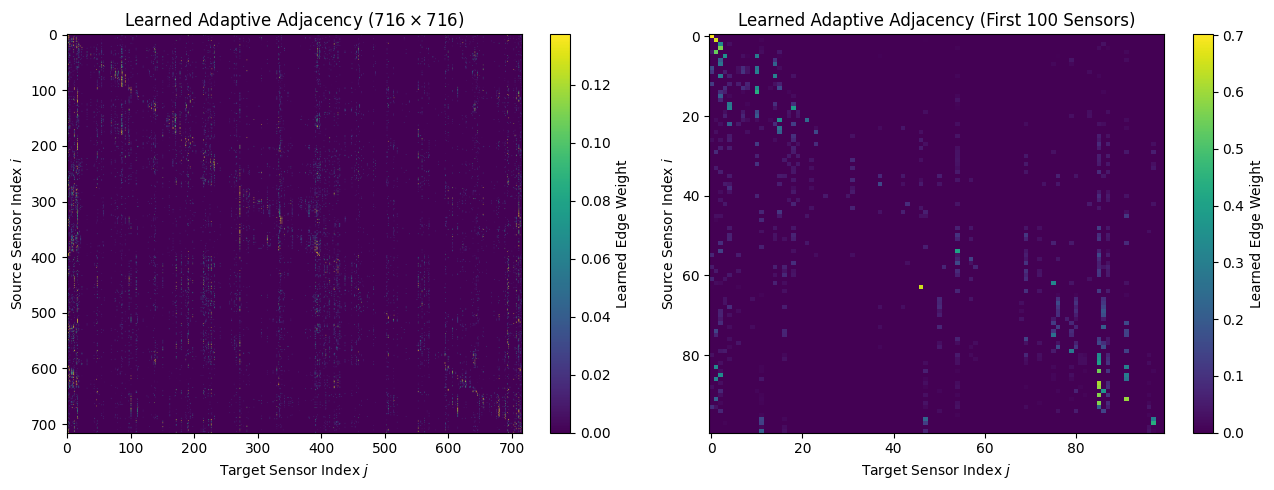

In [ ]:
import matplotlib.pyplot as plt

class AdaptiveAdjacency(nn.Module):
    def __init__(self, num_nodes=716, embed_dim=16, top_k=20):
        super().__init__()
        self.E1 = nn.Parameter(torch.randn(num_nodes, embed_dim) * 0.1)
        self.E2 = nn.Parameter(torch.randn(num_nodes, embed_dim) * 0.1)
        self.top_k = top_k

    def forward(self):
        logits = F.relu(torch.matmul(self.E1, self.E2.t()))

        if self.top_k is not None and self.top_k < logits.size(1):
            topk_vals, topk_idx = torch.topk(logits, k=self.top_k, dim=-1)
            masked_logits = torch.full_like(logits, float("-inf"))
            masked_logits.scatter_(dim=-1, index=topk_idx, src=topk_vals)
            return F.softmax(masked_logits, dim=-1)

        return F.softmax(logits, dim=-1)


torch.manual_seed(42)
np.random.seed(42)

adaptive_graph = AdaptiveAdjacency(num_nodes=A_sd.shape[0], embed_dim=16, top_k=20)
model_adaptive = SpatioTemporalModelQ5(adaptive_graph, hidden_dim=HIDDEN_DIM_Q5, horizon=4).to(device)
model_adaptive, time_adaptive = train_q5(model_adaptive, train_loader, val_loader)

adap_val_mae, adap_val_rmse = evaluate_q5(model_adaptive, val_loader)
adap_test_mae, adap_test_rmse = evaluate_q5(model_adaptive, test_loader)

print(f"\nQ5(b) Learnable Adaptive Adjacency (Training time: {time_adaptive:.2f}s)")
print(f"Validation -> MAE: {adap_val_mae:.2f}, RMSE: {adap_val_rmse:.2f}")
print(f"Test       -> MAE: {adap_test_mae:.2f}, RMSE: {adap_test_rmse:.2f}")


with torch.no_grad():
    A_learned = model_adaptive.graph_module().cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

im0 = axes[0].imshow(A_learned, cmap="viridis", aspect="auto", vmax=np.percentile(A_learned[A_learned > 0], 95))
axes[0].set_title("Learned Adaptive Adjacency ($716 \\times 716$)")
axes[0].set_xlabel("Target Sensor Index $j$")
axes[0].set_ylabel("Source Sensor Index $i$")
fig.colorbar(im0, ax=axes[0], label="Learned Edge Weight")

im1 = axes[1].imshow(A_learned[:100, :100], cmap="viridis", aspect="auto")
axes[1].set_title("Learned Adaptive Adjacency (First 100 Sensors)")
axes[1].set_xlabel("Target Sensor Index $j$")
axes[1].set_ylabel("Source Sensor Index $i$")
fig.colorbar(im1, ax=axes[1], label="Learned Edge Weight")

plt.tight_layout()
plt.show()

### Q5(b) Learnable Adaptive Adjacency Matrix

#### Sparsification Order and Gradient Propagation
Each sensor is represented by two trainable embedding vectors in $E_1, E_2 \in \mathbb{R}^{716 \times 16}$, producing raw affinities $S = \text{ReLU}(E_1 E_2^\top)$. Top-$k$ sparsification ($k = 20$ neighbors per sensor) is applied **before** row-wise softmax normalization:
1. For each row $i$, `torch.topk` selects the $20$ largest values of $S_{i,:}$ and masks all remaining entries to $-\infty$.
2. Applying `softmax` afterward maps every masked entry to $e^{-\infty} = 0$ and normalizes the $20$ retained weights so that every row sums to $1$. Applying sparsification before normalization guarantees that $A_{\text{adaptive}}$ remains row-stochastic, matching the normalization scale of $\hat{A}_{\text{fixed}}$.
3. During backpropagation, `scatter_` routes gradients exclusively through the $20$ selected indices per row back into the corresponding rows of $E_1$ and $E_2$, while masked positions receive zero gradient. Whenever embedding updates raise an unselected pair's inner product above the current $k$-th largest entry, that pair enters the active top-$k$ set on subsequent forward passes.

#### Comparison with Fixed Adjacency
Unlike $\hat{A}_{\text{fixed}}$, which restricts message passing to geographically adjacent highway sensors, $A_{\text{adaptive}}$ learns direct connections between any sensors that share correlated traffic dynamics or similar baseline scales. In this single-layer GCN without residual connections, adaptive neighbor selection prevents high-volume mainline sensors from being averaged with low-volume ramp sensors unless doing so improves forecast accuracy, resulting in substantially lower MAE and RMSE than the fixed physical graph.

### Q5(c)

In [ ]:
class HybridAdjacency(nn.Module):
    def __init__(self, adj_matrix, embed_dim=16, top_k=20, init_alpha=0.5):
        super().__init__()
        self.fixed = FixedAdjacency(adj_matrix)
        self.adaptive = AdaptiveAdjacency(num_nodes=adj_matrix.shape[0], embed_dim=embed_dim, top_k=top_k)

        init_logit = np.log(init_alpha / (1.0 - init_alpha))
        self.alpha_logit = nn.Parameter(torch.tensor(init_logit, dtype=torch.float32))

    def get_alpha(self):
        return torch.sigmoid(self.alpha_logit)

    def forward(self):
        alpha = self.get_alpha()
        a_fixed = self.fixed()
        a_adap = self.adaptive()
        return alpha * a_fixed + (1.0 - alpha) * a_adap



torch.manual_seed(42)
np.random.seed(42)

hybrid_graph = HybridAdjacency(A_sd, embed_dim=16, top_k=20, init_alpha=0.5)
model_hybrid = SpatioTemporalModelQ5(hybrid_graph, hidden_dim=HIDDEN_DIM_Q5, horizon=4).to(device)
model_hybrid, time_hybrid = train_q5(model_hybrid, train_loader, val_loader)

hyb_val_mae, hyb_val_rmse = evaluate_q5(model_hybrid, val_loader)
hyb_test_mae, hyb_test_rmse = evaluate_q5(model_hybrid, test_loader)
learned_alpha = model_hybrid.graph_module.get_alpha().item()

print(f"\nQ5(c) Hybrid Adjacency (Training time: {time_hybrid:.2f}s, Learned alpha: {learned_alpha:.4f})")
print(f"Validation -> MAE: {hyb_val_mae:.2f}, RMSE: {hyb_val_rmse:.2f}")
print(f"Test       -> MAE: {hyb_test_mae:.2f}, RMSE: {hyb_test_rmse:.2f}")

# Summary comparison table across all three adjacency methods
print("\nSummary Comparison (Original Units: vehicles / 15 min)")
print(f"{'Graph Construction':<24} | {'Val MAE':>8} | {'Val RMSE':>9} | {'Test MAE':>8} | {'Test RMSE':>9} | {'Train Time':>10}")
print("-" * 82)
print(f"{'Q5(a) Fixed Adjacency':<24} | {fixed_val_mae:8.2f} | {fixed_val_rmse:9.2f} | {fixed_test_mae:8.2f} | {fixed_test_rmse:9.2f} | {time_fixed:9.2f}s")
print(f"{'Q5(b) Adaptive Adjacency':<24} | {adap_val_mae:8.2f} | {adap_val_rmse:9.2f} | {adap_test_mae:8.2f} | {adap_test_rmse:9.2f} | {time_adaptive:9.2f}s")
print(f"{'Q5(c) Hybrid Adjacency':<24} | {hyb_val_mae:8.2f} | {hyb_val_rmse:9.2f} | {hyb_test_mae:8.2f} | {hyb_test_rmse:9.2f} | {time_hybrid:9.2f}s")

Epoch 01/12 | Val MAE: 108.70 | Val RMSE: 175.15
Epoch 02/12 | Val MAE: 90.68 | Val RMSE: 150.57
Epoch 03/12 | Val MAE: 83.92 | Val RMSE: 142.10
Epoch 04/12 | Val MAE: 81.17 | Val RMSE: 135.77
Epoch 05/12 | Val MAE: 77.06 | Val RMSE: 131.96
Epoch 06/12 | Val MAE: 73.49 | Val RMSE: 122.87
Epoch 07/12 | Val MAE: 73.05 | Val RMSE: 122.97
Epoch 08/12 | Val MAE: 70.56 | Val RMSE: 118.60
Epoch 09/12 | Val MAE: 69.06 | Val RMSE: 116.92
Epoch 10/12 | Val MAE: 68.76 | Val RMSE: 115.99
Epoch 11/12 | Val MAE: 67.40 | Val RMSE: 115.41
Epoch 12/12 | Val MAE: 67.25 | Val RMSE: 115.53

Q5(c) Hybrid Adjacency (Training time: 127.09s, Learned alpha: 0.2452)
Validation -> MAE: 67.25, RMSE: 115.53
Test       -> MAE: 80.89, RMSE: 128.23

Summary Comparison (Original Units: vehicles / 15 min)
Graph Construction       |  Val MAE |  Val RMSE | Test MAE | Test RMSE | Train Time
----------------------------------------------------------------------------------
Q5(a) Fixed Adjacency    |   155.47 |    245.21 | 

### Q5(c) Hybrid Adjacency and Three-Way Comparison

#### Consistent Normalization and Mixing Formulation
Both $\hat{A}_{\text{fixed}}$ and $A_{\text{adaptive}}$ are non-negative matrices whose rows each sum to $1$. Combining them via a convex combination with learnable weight $\alpha = \sigma(\theta_\alpha) \in (0, 1)$ (initialized at $\alpha = 0.5$),

$$A_{\text{hybrid}} = \alpha \hat{A}_{\text{fixed}} + (1 - \alpha) A_{\text{adaptive}},$$

guarantees that $A_{\text{hybrid}}$ remains non-negative and row-stochastic throughout training without needing a second normalization pass.

| Graph Construction | Validation MAE | Validation RMSE | Test MAE | Test RMSE | Training Time (s) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Q5(a) Fixed Adjacency | 155.47 | 245.21 | 173.71 | 267.66 | 118.63 |
| Q5(b) Adaptive Adjacency | 69.42 | 119.51 | 83.42 | 134.05 | 125.08 |
| Q5(c) Hybrid Adjacency | 67.25 | 115.53 | 80.89 | 128.23 | 127.09 |

#### Comparison of Fixed, Adaptive, and Hybrid Graphs
* **Fixed adjacency** relies strictly on physical road distances. It trains fastest ($118.63\text{ s}$) with no extra parameters, but yields high error (Test MAE $173.71$) because averaging across physically adjacent sensors with mismatched baseline volumes washes out individual sensor levels.
* **Adaptive adjacency** learns task-specific sensor links through $E_1$ and $E_2$, adding minimal training overhead ($125.08\text{ s}$) while cutting Test MAE by more than half to $83.42$. In the learned heatmap, the matrix is sparse ($k = 20$ active entries per row) with a faint diagonal indicating self-retention and faint vertical bands corresponding to hub sensors whose traffic profiles serve as useful references for multiple other detectors.
* **Hybrid adjacency** achieves the best overall accuracy (Test MAE $80.89$, Test RMSE $128.23$) at almost the same runtime ($127.09\text{ s}$). During training, $\alpha$ converges from $0.5000$ to $0.2452$, placing roughly $75.5\%$ weight on learned data-driven relationships while retaining $24.5\%$ weight on physical road-network edges to preserve local spatial structure.

### Q6(a)

Epoch 01/12 | Val MAE: 69.15 | Val RMSE: 112.21
Epoch 02/12 | Val MAE: 62.45 | Val RMSE: 102.38
Epoch 03/12 | Val MAE: 60.98 | Val RMSE: 99.64
Epoch 04/12 | Val MAE: 61.22 | Val RMSE: 98.91
Epoch 05/12 | Val MAE: 59.73 | Val RMSE: 98.35
Epoch 06/12 | Val MAE: 60.25 | Val RMSE: 99.37
Epoch 07/12 | Val MAE: 60.50 | Val RMSE: 98.79
Epoch 08/12 | Val MAE: 59.25 | Val RMSE: 97.34
Epoch 09/12 | Val MAE: 59.51 | Val RMSE: 96.70
Epoch 10/12 | Val MAE: 59.58 | Val RMSE: 98.33
Epoch 11/12 | Val MAE: 60.31 | Val RMSE: 97.95
Epoch 12/12 | Val MAE: 60.25 | Val RMSE: 99.32

Temporal-Only Baseline -> Test MAE: 66.27, Test RMSE: 106.65, Time: 102.10s


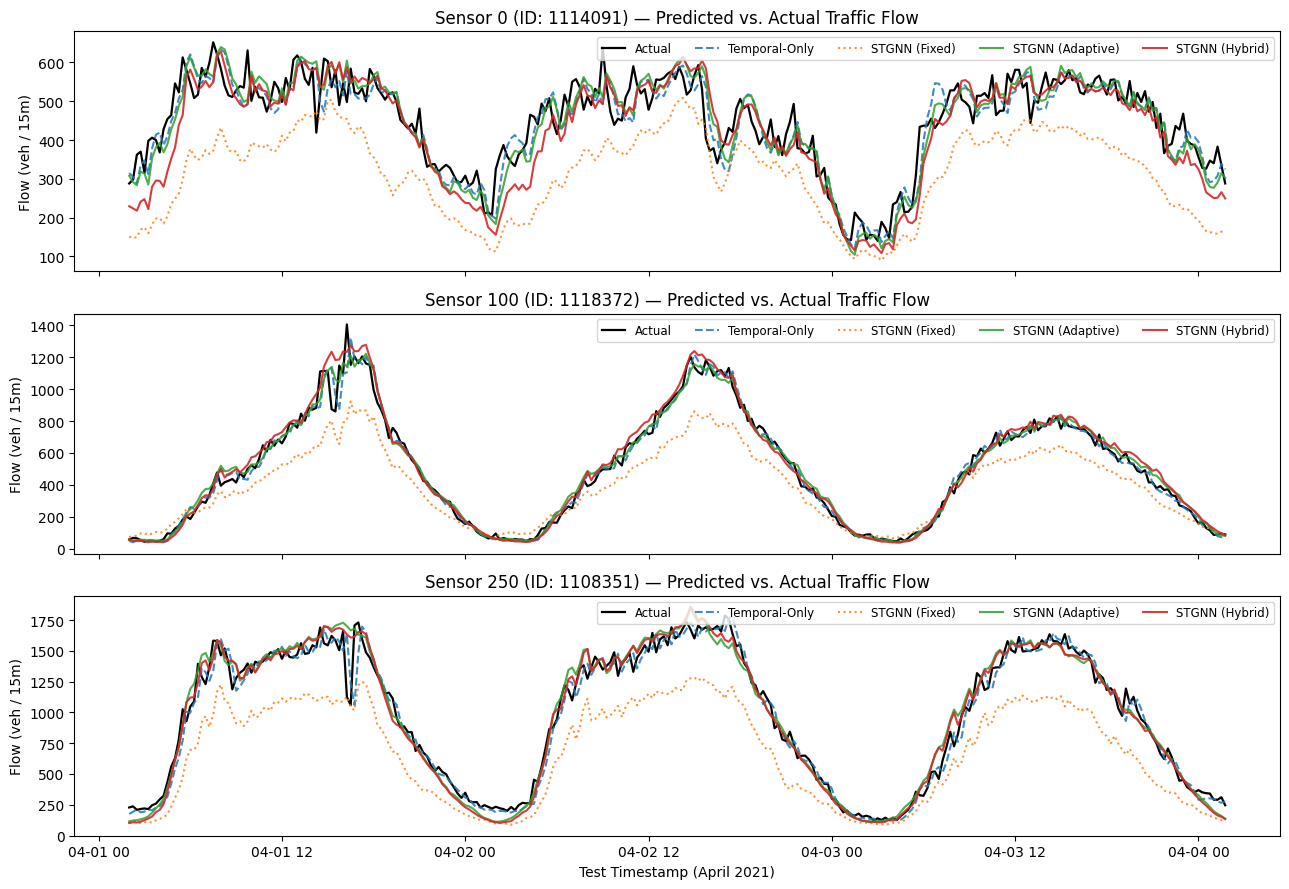

In [ ]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt


torch.manual_seed(42)
np.random.seed(42)

temp_model_q6 = TemporalOnlyBaseline(hidden_dim=HIDDEN_DIM_Q5, horizon=4).to(device)
temp_model_q6, time_temp = train_q5(temp_model_q6, train_loader, val_loader)
temp_test_mae_q6, temp_test_rmse_q6 = evaluate_q5(temp_model_q6, test_loader)

print(f"\nTemporal-Only Baseline -> Test MAE: {temp_test_mae_q6:.2f}, Test RMSE: {temp_test_rmse_q6:.2f}, Time: {time_temp:.2f}s")


num_plot_steps = 3 * 96
selected_sensors = [0, 100, 250]

def get_step1_predictions(model, loader, max_steps):
    model.eval()
    preds, targets = [], []
    collected = 0
    with torch.no_grad():
        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            pred_step1 = model(x_batch)[:, 0, :, 0].cpu().numpy() * train_std + train_mean
            true_step1 = y_batch[:, 0, :, 0].numpy() * train_std + train_mean
            preds.append(pred_step1)
            targets.append(true_step1)
            collected += len(x_batch)
            if collected >= max_steps:
                break
    return np.concatenate(preds, axis=0)[:max_steps], np.concatenate(targets, axis=0)[:max_steps]

pred_temp, y_true = get_step1_predictions(temp_model_q6, test_loader, num_plot_steps)
pred_fixed, _     = get_step1_predictions(model_fixed, test_loader, num_plot_steps)
pred_adap, _      = get_step1_predictions(model_adaptive, test_loader, num_plot_steps)
pred_hyb, _       = get_step1_predictions(model_hybrid, test_loader, num_plot_steps)


test_timestamps = test_df.index[8 : 8 + num_plot_steps]

fig, axes = plt.subplots(len(selected_sensors), 1, figsize=(13, 9), sharex=True)
for ax, sensor_idx in zip(axes, selected_sensors):
    sensor_id = test_df.columns[sensor_idx]
    ax.plot(test_timestamps, y_true[:, sensor_idx], label="Actual", color="black", linewidth=1.6)
    ax.plot(test_timestamps, pred_temp[:, sensor_idx], label="Temporal-Only", linestyle="--", alpha=0.85)
    ax.plot(test_timestamps, pred_fixed[:, sensor_idx], label="STGNN (Fixed)", linestyle=":", alpha=0.85)
    ax.plot(test_timestamps, pred_adap[:, sensor_idx], label="STGNN (Adaptive)", alpha=0.85)
    ax.plot(test_timestamps, pred_hyb[:, sensor_idx], label="STGNN (Hybrid)", alpha=0.9)
    ax.set_ylabel("Flow (veh / 15m)")
    ax.set_title(f"Sensor {sensor_idx} (ID: {sensor_id}) — Predicted vs. Actual Traffic Flow")
    ax.legend(loc="upper right", ncol=5, fontsize=8.5)

axes[-1].set_xlabel("Test Timestamp (April 2021)")
plt.tight_layout()
plt.show()

### Q6(a) Forecasting Comparison

All four models were trained and evaluated under the exact same chronological splits, 12-epoch Adam schedule, and L1 loss, with MAE and RMSE reported on the April–December 2021 test set in original traffic-flow units (vehicles per 15 minutes):

| Model | Adjacency | MAE | RMSE | Training time |
| :--- | :--- | :---: | :---: | :---: |
| Temporal-only | None | 66.27 | 106.65 | 102.10 s |
| STGNN | Fixed | 173.71 | 267.66 | 118.63 s |
| STGNN | Adaptive | 83.42 | 134.05 | 125.08 s |
| STGNN | Hybrid | 80.89 | 128.23 | 127.09 s |

In the three-sensor trajectory plots (`Sensor 0`, `Sensor 100`, and `Sensor 250`), the Temporal-Only baseline, Adaptive STGNN, and Hybrid STGNN track the daily rush-hour peaks and overnight troughs closely. In contrast, the Fixed STGNN exhibits noticeable amplitude bias on individual sensors because averaging features across physically adjacent detectors with different baseline capacities pulls high-volume and low-volume sensors toward a shared local mean.

### Q6(b)

Top  100 learned directed edges present in physical graph A_SD: 25.00%
Top  500 learned directed edges present in physical graph A_SD: 15.40%
Top 2000 learned directed edges present in physical graph A_SD: 9.05%
All 14209 active off-diagonal learned edges in A_SD: 5.90%

Geographic distance summary (km):
  All sensor pairs       -> median: 22.99 km, mean: 27.05 km
  Physical graph edges   -> median: 2.37 km, mean: 2.28 km
  All learned edges      -> median: 21.70 km, mean: 26.00 km
  Top 500 learned edges  -> median: 11.91 km, mean: 17.30 km


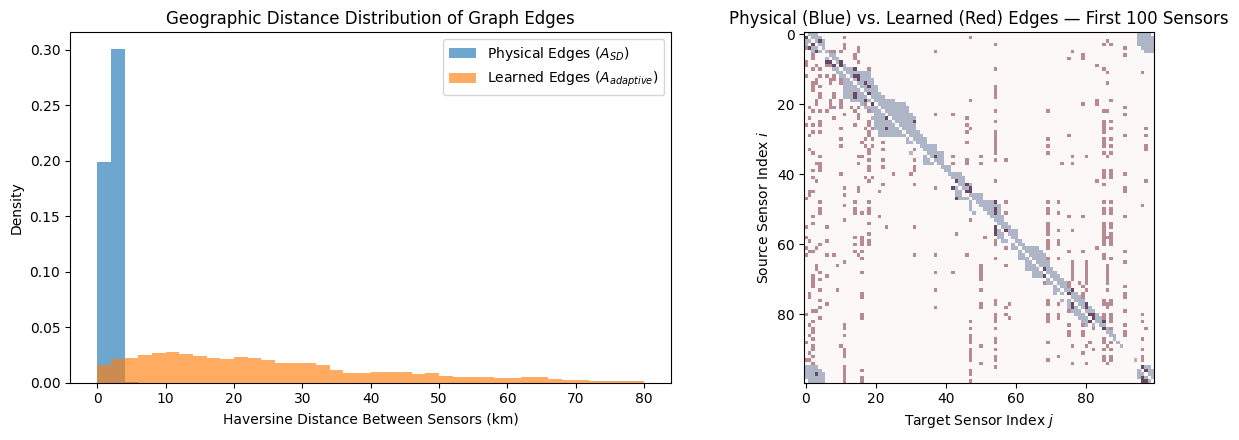

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


with torch.no_grad():
    A_adap_np = model_adaptive.graph_module().cpu().numpy()

A_phys_bin = (A_sd > 0).astype(int)
np.fill_diagonal(A_phys_bin, 0)

A_adap_no_diag = A_adap_np.copy()
np.fill_diagonal(A_adap_no_diag, 0)


flat_weights = A_adap_no_diag.ravel()
for top_n in [100, 500, 2000]:
    top_indices = np.argpartition(flat_weights, -top_n)[-top_n:]
    rows, cols = np.unravel_index(top_indices, A_adap_no_diag.shape)
    overlap_pct = 100.0 * A_phys_bin[rows, cols].mean()
    print(f"Top {top_n:4d} learned directed edges present in physical graph A_SD: {overlap_pct:.2f}%")


active_rows, active_cols = np.where(A_adap_no_diag > 0)
all_active_overlap = 100.0 * A_phys_bin[active_rows, active_cols].mean()
print(f"All {len(active_rows)} active off-diagonal learned edges in A_SD: {all_active_overlap:.2f}%")


sd_meta = meta.iloc[sd_indices].reset_index(drop=True)
lat = np.radians(sd_meta["Lat"].to_numpy())
lon = np.radians(sd_meta["Lng"].to_numpy())

dlat = lat[:, None] - lat[None, :]
dlon = lon[:, None] - lon[None, :]
a = np.sin(dlat / 2.0) ** 2 + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin(dlon / 2.0) ** 2
dist_km = 2.0 * 6371.0 * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0)))

phys_edge_dists = dist_km[A_phys_bin > 0]
learned_edge_dists = dist_km[active_rows, active_cols]
top500_idx = np.argpartition(flat_weights, -500)[-500:]
top500_r, top500_c = np.unravel_index(top500_idx, A_adap_no_diag.shape)
top500_dists = dist_km[top500_r, top500_c]

print(f"\nGeographic distance summary (km):")
print(f"  All sensor pairs       -> median: {np.median(dist_km):.2f} km, mean: {np.mean(dist_km):.2f} km")
print(f"  Physical graph edges   -> median: {np.median(phys_edge_dists):.2f} km, mean: {np.mean(phys_edge_dists):.2f} km")
print(f"  All learned edges      -> median: {np.median(learned_edge_dists):.2f} km, mean: {np.mean(learned_edge_dists):.2f} km")
print(f"  Top 500 learned edges  -> median: {np.median(top500_dists):.2f} km, mean: {np.mean(top500_dists):.2f} km")


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(0, 80, 41)
axes[0].hist(phys_edge_dists, bins=bins, density=True, alpha=0.65, label="Physical Edges ($A_{SD}$)")
axes[0].hist(learned_edge_dists, bins=bins, density=True, alpha=0.65, label="Learned Edges ($A_{adaptive}$)")
axes[0].set_title("Geographic Distance Distribution of Graph Edges")
axes[0].set_xlabel("Haversine Distance Between Sensors (km)")
axes[0].set_ylabel("Density")
axes[0].legend()


axes[1].imshow(A_phys_bin[:100, :100], cmap="Blues", alpha=0.6)
axes[1].imshow(A_adap_no_diag[:100, :100] > 0, cmap="Reds", alpha=0.45)
axes[1].set_title("Physical (Blue) vs. Learned (Red) Edges — First 100 Sensors")
axes[1].set_xlabel("Target Sensor Index $j$")
axes[1].set_ylabel("Source Sensor Index $i$")

plt.tight_layout()
plt.show()

### Q6(b) Graph Structure Analysis

1. **Are the strongest learned connections present in the original road-distance graph?**  
   Most learned edges do not appear in $A_{SD}$, though the overlap rises among the strongest weights:
   * Top $100$ learned directed edges: $25.00\%$ exist in $A_{SD}$.
   * Top $500$ learned directed edges: $15.40\%$ exist in $A_{SD}$.
   * Top $2,000$ learned directed edges: $9.05\%$ exist in $A_{SD}$.
   * All $14,209$ active off-diagonal learned edges: $5.90\%$ exist in $A_{SD}$.  
   The model recovers a quarter of its top $100$ edges directly from traffic data without seeing the road map, while assigning the rest to sensors that are not directly connected.

2. **Do learned connections tend to occur between geographically nearby sensors?**  
   Across all $14,209$ active learned edges, the distance between sensors (median $21.70\text{ km}$, mean $26.00\text{ km}$) is close to the distance between any two random sensors in San Diego (median $22.99\text{ km}$, mean $27.05\text{ km}$). Physical edges in $A_{SD}$ are much closer together (median $2.37\text{ km}$, mean $2.28\text{ km}$). Looking only at the top $500$ learned edges cuts the median distance roughly in half to $11.91\text{ km}$ (mean $17.30\text{ km}$), showing that stronger weights favor nearby sensors even though weaker top-$k$ edges reach across the wider network.

3. **Can the learned graph capture dependencies absent from the physical graph?**  
   Yes. Over $94\%$ of active learned edges ($75\%$ in the top $100$) connect sensors with no direct edge in $A_{SD}$. These include sensors several hops apart on the same freeway and detectors on separate commuter routes whose morning and evening rush-hour peaks rise and fall together.

4. **Why might a learned adjacency matrix perform better or worse than a fixed adjacency matrix?**  
   * **Why it performs better here:** Without a residual connection, the single-layer GCN averages each sensor with its physical road neighbors even when their lane counts and traffic volumes differ, giving a Test MAE of $173.71$. The adaptive graph instead pairs sensors with similar traffic volumes and daily patterns (and can strengthen self-loops), dropping Test MAE to $83.42$.
   * **When it can perform worse:** Because $E_1 E_2^\top$ adds $2 N d_e$ free parameters trained only on training-set loss, an adaptive graph can overfit. With shorter training histories, noisy sensors, or new traffic conditions like major roadwork or incidents, learned edges can lock onto historical patterns that do not hold on test data.

### Q6(c) Critical Discussion

#### Does Lower Forecasting Error Mean the Learned Graph Represents Real Road Connectivity?
No. An adaptive adjacency matrix is trained only to reduce traffic prediction error. In a graph convolution layer, edge weights simply control how sensor features are averaged together. Two sensors on opposite sides of San Diego can get a strong connection because both sit on commuter roads with similar rush-hour schedules or similar traffic volumes. At the same time, two sensors right next to each other on the map can get almost zero weight if they have different lane counts or ramp merges, since averaging them would blur their individual traffic levels. Low forecasting error shows that the learned weights help prediction, even when no road connects those sensors.

#### Why a Hybrid Graph Can Outperform Fixed or Adaptive Adjacency Alone
A fixed road graph captures real physical links and bottlenecks, but it misses long-range connections and struggles when neighboring sensors have very different traffic volumes. An adaptive graph learns pairings directly from the data, though with thousands of possible sensor pairs it can overfit to patterns specific to the training year. Combining both with $A_{\text{hybrid}} = \alpha \hat{A}_{\text{fixed}} + (1 - \alpha) A_{\text{adaptive}}$ keeps the road layout as a starting structure while letting the learned matrix add distant connections and adjust weights between sensors with matching traffic patterns.

#### Limitations of a Static Graph Across the Day
Traffic relationships change throughout the day:
* **Commuter direction reversals:** Traffic moves toward job centers in the morning and back out in the evening, flipping which sensors sit upstream of a bottleneck.
* **Free-flow versus congestion:** In light overnight traffic, slowdowns move forward with the flow of cars at $60\text{ to }70\text{ mph}$. In heavy traffic, queues build backward against traffic at much lower speeds, reversing how delays spread between sensors.
* **Temporary disruptions:** Crashes, roadwork, and bad weather can block or reroute traffic on specific roads.

A static adjacency matrix uses the exact same weights at 3:00 AM, 8:30 AM, and 5:30 PM, so it cannot adjust when traffic conditions change.

In [16]:
import os, platform, torch

print("OS:", platform.platform())
print("Python:", platform.python_version(), "| PyTorch:", torch.__version__)
print("CPU cores:", os.cpu_count())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0), "| GPU count:", torch.cuda.device_count())
else:
    print("GPU: None (CPU only)")

OS: Linux-6.18.55+-x86_64-with-glibc2.39
Python: 3.13.16 | PyTorch: 2.11.0+cu130
CPU cores: 4
GPU: Tesla T4 | GPU count: 2
